# Лабораторная работа №2. Генерация карты по спутниковому снимку

Задача: обучить pix2pix преобразовывать **спутниковый снимок в схематическую карту**.

[Задание](https://github.com/JustHawker/AIT_Course_SamU_2026/blob/autumn-2026/Лабораторные/ЛР2.md) ·
[Источник данных maps](https://efrosgans.eecs.berkeley.edu/pix2pix/datasets/) ·
[Проект pix2pix](https://github.com/phillipi/pix2pix).

## 1. Библиотеки и параметры обработки

In [11]:
from pathlib import Path
import json
import random
import tarfile
import urllib.request

import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
import torch.nn.functional as F
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import functional as TF

SEED = 42
IMAGE_SIZE = 256
JITTER_SIZE = 286
BATCH_SIZE = 4
EPOCHS = 100
LEARNING_RATE = 2e-4
LAMBDA_L1 = 100
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(SEED)

DATA_ROOT = Path('datasets')
MAPS_DIR = DATA_ROOT / 'maps'
ARCHIVE_PATH = DATA_ROOT / 'maps.tar.gz'
SPLIT_PATH = MAPS_DIR / 'split.json'
RESULTS_DIR = Path('runs/pix2pix_maps')
DATA_ROOT.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Устройство:', DEVICE)

Устройство: cuda


## 2. Загрузка maps и разделение выборки
В каждом JPG рядом расположены два изображения одной территории:
**слева спутниковый снимок, справа карта**. Разрезаем файл по середине ширины.

Из исходной папки `train` выделяем 10% пар для validation; папку `val` из архива
используем целиком как test. Это наше разбиение: `val` в архиве и validation
в ноутбуке — разные выборки. Test оставляем для окончательной оценки модели.
Имена файлов сохраняем в `datasets/maps/split.json`, не копируя сами изображения.

In [12]:
if not (MAPS_DIR / 'train').exists():
    if not ARCHIVE_PATH.exists():
        print('Загрузка maps...')
        temporary = ARCHIVE_PATH.with_suffix('.gz.part')
        urllib.request.urlretrieve(
            'https://efrosgans.eecs.berkeley.edu/pix2pix/datasets/maps.tar.gz', temporary)
        temporary.replace(ARCHIVE_PATH)
    with tarfile.open(ARCHIVE_PATH, 'r:*') as archive:
        archive.extractall(DATA_ROOT, filter='data')

if not SPLIT_PATH.exists():
    files = sorted(path.relative_to(MAPS_DIR).as_posix() for path in (MAPS_DIR / 'train').glob('*.jpg'))
    random.Random(SEED).shuffle(files)
    n_val = round(len(files) * 0.1)
    splits = {
        'train': files[n_val:],
        'val': files[:n_val],
        'test': sorted(path.relative_to(MAPS_DIR).as_posix() for path in (MAPS_DIR / 'val').glob('*.jpg')),
    }
    SPLIT_PATH.write_text(json.dumps(splits, indent=2), encoding='utf-8')

splits = json.loads(SPLIT_PATH.read_text(encoding='utf-8'))
for name, files in splits.items():
    print(f'{name}: {len(files)} пар')

train: 986 пар
val: 110 пар
test: 1098 пар


## 3. Подготовка пар и просмотр примеров
Для train применяем одинаковые преобразования к снимку и карте: увеличение
до 286×286, случайный фрагмент 256×256 и горизонтальное отражение. Общие
координаты фрагмента и общее решение об отражении сохраняют соответствие объектов.

In [13]:
class MapsDataset(Dataset):
    def __init__(self, filenames, augment=False):
        self.filenames = filenames
        self.augment = augment

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):
        with Image.open(MAPS_DIR / self.filenames[index]) as image:
            image = image.convert('RGB')
        width, height = image.size
        satellite = image.crop((0, 0, width // 2, height))
        target_map = image.crop((width // 2, 0, width, height))

        if self.augment:
            satellite = satellite.resize((JITTER_SIZE, JITTER_SIZE), Image.Resampling.BICUBIC)
            target_map = target_map.resize((JITTER_SIZE, JITTER_SIZE), Image.Resampling.BICUBIC)
            top, left, crop_h, crop_w = transforms.RandomCrop.get_params(
                satellite, output_size=(IMAGE_SIZE, IMAGE_SIZE))
            satellite = TF.crop(satellite, top, left, crop_h, crop_w)
            target_map = TF.crop(target_map, top, left, crop_h, crop_w)
            if torch.rand(()).item() < 0.5:
                satellite = TF.hflip(satellite)
                target_map = TF.hflip(target_map)
        else:
            satellite = satellite.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BICUBIC)
            target_map = target_map.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BICUBIC)

        return TF.to_tensor(satellite) * 2 - 1, TF.to_tensor(target_map) * 2 - 1


train_dataset = MapsDataset(splits['train'], augment=True)
val_dataset = MapsDataset(splits['val'])
test_dataset = MapsDataset(splits['test'])
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, num_workers=0)

satellites, maps = next(iter(train_loader))
print('Спутниковые снимки:', tuple(satellites.shape))
print('Карты:', tuple(maps.shape))

Спутниковые снимки: (4, 3, 256, 256)
Карты: (4, 3, 256, 256)


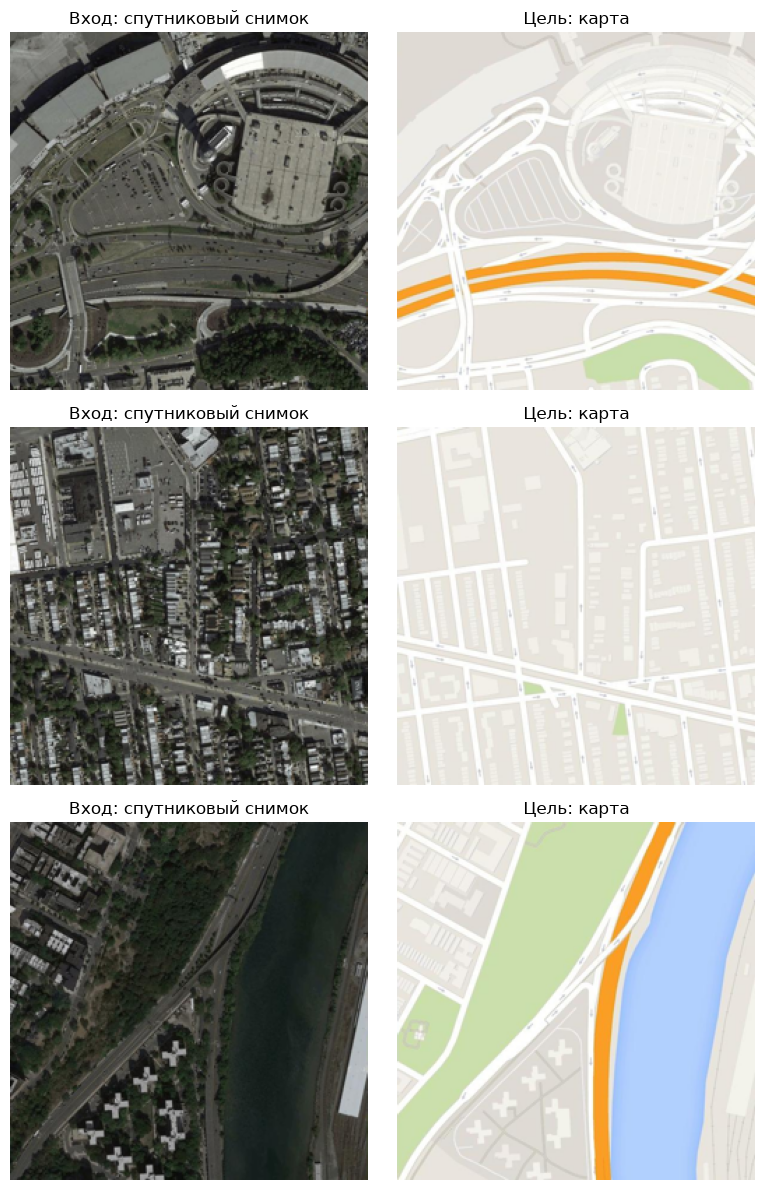

In [14]:
def to_image(tensor):
    return ((tensor.detach().cpu() + 1) / 2).clamp(0, 1).permute(1, 2, 0).numpy()


fig, axes = plt.subplots(3, 2, figsize=(8, 12))
for row in range(3):
    satellite, target_map = val_dataset[row]
    for ax, tensor, title in zip(axes[row], [satellite, target_map],
                                 ['Вход: спутниковый снимок', 'Цель: карта']):
        ax.imshow(to_image(tensor))
        ax.set_title(title)
        ax.axis('off')
plt.tight_layout()
fig.savefig(RESULTS_DIR / 'dataset_examples.png', dpi=120)
plt.show()

## 4. Генератор U-Net и условный дискриминатор
Используем архитектуру [pix2pix](https://arxiv.org/abs/1611.07004):
U-Net с восемью уровнями уменьшения размера и skip-связями между encoder и decoder.
Три первых блока decoder содержат Dropout(0.5). Выходной Tanh даёт RGB в [-1, 1].

Дискриминатор **PatchGAN 70×70** получает 6 каналов: спутниковый снимок и настоящую
или сгенерированную карту. Для входа 256×256 он выдаёт сетку логитов 30×30.
Sigmoid отдельно не добавляем: он включён в BCEWithLogitsLoss.

In [15]:
def down_block(in_channels, out_channels, normalize=True):
    layers = [nn.Conv2d(in_channels, out_channels, 4, stride=2, padding=1, bias=False)]
    if normalize:
        layers.append(nn.BatchNorm2d(out_channels))
    layers.append(nn.LeakyReLU(0.2))
    return nn.Sequential(*layers)


def up_block(in_channels, out_channels, dropout=0.0):
    return nn.Sequential(
        nn.ReLU(),
        nn.ConvTranspose2d(in_channels, out_channels, 4, stride=2, padding=1, bias=False),
        nn.BatchNorm2d(out_channels), nn.Dropout(dropout),
    )


class UNetGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.ModuleList([
            down_block(3, 64, normalize=False),   # 256 → 128
            down_block(64, 128),                 # 128 → 64
            down_block(128, 256),                # 64 → 32
            down_block(256, 512),                # 32 → 16
            down_block(512, 512),                # 16 → 8
            down_block(512, 512),                # 8 → 4
            down_block(512, 512),                # 4 → 2
            down_block(512, 512, normalize=False),  # 2 → 1
        ])
        self.decoder = nn.ModuleList([
            up_block(512, 512, dropout=0.5),
            up_block(1024, 512, dropout=0.5),
            up_block(1024, 512, dropout=0.5),
            up_block(1024, 512),
            up_block(1024, 256),
            up_block(512, 128),
            up_block(256, 64),
        ])
        self.output = nn.Sequential(
            nn.ReLU(), nn.ConvTranspose2d(128, 3, 4, stride=2, padding=1), nn.Tanh())

    def forward(self, satellite):
        features = []
        x = satellite
        for block in self.encoder:
            x = block(x)
            features.append(x)
        for block, skip in zip(self.decoder, reversed(features[:-1])):
            x = torch.cat([block(x), skip], dim=1)
        return self.output(x)


def discriminator_block(in_channels, out_channels, stride):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 4, stride=stride, padding=1, bias=False),
        nn.BatchNorm2d(out_channels), nn.LeakyReLU(0.2),
    )


class PatchDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(6, 64, 4, stride=2, padding=1), nn.LeakyReLU(0.2),
            discriminator_block(64, 128, 2),
            discriminator_block(128, 256, 2),
            discriminator_block(256, 512, 1),
            nn.Conv2d(512, 1, 4, stride=1, padding=1),
        )

    def forward(self, satellite, target_map):
        return self.model(torch.cat([satellite, target_map], dim=1))


def initialize_weights(layer):
    if isinstance(layer, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(layer.weight, mean=0.0, std=0.02)
        if layer.bias is not None:
            nn.init.zeros_(layer.bias)
    elif isinstance(layer, nn.BatchNorm2d):
        nn.init.normal_(layer.weight, mean=1.0, std=0.02)
        nn.init.zeros_(layer.bias)

## 5. Ошибка восстановления и примеры карт
Цель генератора: `BCE(D(снимок, результат), 1) + 100 × L1(результат, карта)`.
Дискриминатор учится отличать настоящую пару от пары с результатом генератора.

Для выбора весов используем **validation L1 в диапазоне изображений [-1, 1]**.
Дополнительно считаем PSNR в RGB [0, 1] на всём изображении без обрезки границ;
визуально оцениваем соответствие дорог, зданий и водоёмов.

In [16]:
@torch.no_grad()
def evaluate_maps(generator, loader):
    generator.eval()
    l1_sum, psnr_sum, count = 0.0, 0.0, 0
    for satellite, target_map in loader:
        satellite, target_map = satellite.to(DEVICE), target_map.to(DEVICE)
        prediction = generator(satellite)
        l1_sum += F.l1_loss(prediction, target_map).item() * len(satellite)
        mse = ((prediction - target_map) / 2).square().mean(dim=(1, 2, 3))
        psnr_sum += (-10 * torch.log10(mse.clamp_min(1e-12))).sum().item()
        count += len(satellite)
    return {'l1': l1_sum / count, 'psnr': psnr_sum / count}


@torch.no_grad()
def save_map_examples(generator, dataset, destination, indices=(0, 1, 2)):
    generator.eval()
    fig, axes = plt.subplots(len(indices), 3, figsize=(11, 3.5 * len(indices)), squeeze=False)
    for row, index in enumerate(indices):
        satellite, target_map = dataset[index]
        prediction = generator(satellite.unsqueeze(0).to(DEVICE))[0]
        for ax, tensor, title in zip(axes[row], [satellite, prediction, target_map],
                                    ['Спутниковый снимок', 'Карта pix2pix', 'Эталонная карта']):
            ax.imshow(to_image(tensor))
            ax.set_title(title)
            ax.axis('off')
    fig.tight_layout()
    fig.savefig(destination, dpi=120)
    plt.close(fig)
    return Path(destination)

## 6. Обучение pix2pix
Начальные параметры: 100 эпох,
batch size 4, Adam с learning rate 0.0002 и β=(0.5, 0.999). Первую половину эпох
скорость постоянна, затем линейно уменьшается.

В каждой итерации сначала обновляем D на настоящей и сгенерированной паре,
затем G. На шаге G параметры и статистика BatchNorm у D заморожены,
но градиент через D проходит к G.

После каждой эпохи сохраняем `last_generator.pt`, лучшую по validation L1 модель
`best_generator.pt`, историю `history.json` и примеры в `samples`.

In [7]:
torch.manual_seed(SEED)
G = UNetGenerator().to(DEVICE)
D = PatchDiscriminator().to(DEVICE)
G.apply(initialize_weights)
D.apply(initialize_weights)
optimizer_g = torch.optim.Adam(G.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
optimizer_d = torch.optim.Adam(D.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()

def lr_factor(epoch):
    return min(1.0, max(0.0, (EPOCHS - epoch) / max(1, EPOCHS - EPOCHS // 2)))

scheduler_g = torch.optim.lr_scheduler.LambdaLR(optimizer_g, lr_factor)
scheduler_d = torch.optim.lr_scheduler.LambdaLR(optimizer_d, lr_factor)
history = {'g_loss': [], 'd_loss': [], 'train_l1': [], 'val_l1': [], 'val_psnr': []}
best_l1 = float('inf')
(RESULTS_DIR / 'samples').mkdir(parents=True, exist_ok=True)

for epoch in range(EPOCHS):
    G.train()
    total_g, total_d, total_l1 = 0.0, 0.0, 0.0
    for satellite, target_map in tqdm(train_loader, desc=f'pix2pix {epoch + 1}/{EPOCHS}'):
        satellite, target_map = satellite.to(DEVICE), target_map.to(DEVICE)
        optimizer_g.zero_grad(set_to_none=True)
        prediction = G(satellite)

        D.train()
        D.requires_grad_(True)
        optimizer_d.zero_grad(set_to_none=True)
        real_logits = D(satellite, target_map)
        fake_logits = D(satellite, prediction.detach())
        loss_d = (bce(real_logits, torch.ones_like(real_logits))
                  + bce(fake_logits, torch.zeros_like(fake_logits))) / 2
        loss_d.backward()
        optimizer_d.step()
        optimizer_d.zero_grad(set_to_none=True)

        D.eval()
        D.requires_grad_(False)
        logits = D(satellite, prediction)
        loss_l1 = F.l1_loss(prediction, target_map)
        loss_g = bce(logits, torch.ones_like(logits)) + LAMBDA_L1 * loss_l1
        loss_g.backward()
        optimizer_g.step()
        total_g += loss_g.item() * len(satellite)
        total_d += loss_d.item() * len(satellite)
        total_l1 += loss_l1.item() * len(satellite)

    metrics = evaluate_maps(G, val_loader)
    history['g_loss'].append(total_g / len(train_dataset))
    history['d_loss'].append(total_d / len(train_dataset))
    history['train_l1'].append(total_l1 / len(train_dataset))
    history['val_l1'].append(metrics['l1'])
    history['val_psnr'].append(metrics['psnr'])
    torch.save(G.state_dict(), RESULTS_DIR / 'last_generator.pt')
    if metrics['l1'] < best_l1:
        best_l1 = metrics['l1']
        torch.save(G.state_dict(), RESULTS_DIR / 'best_generator.pt')
    (RESULTS_DIR / 'history.json').write_text(json.dumps(history, indent=2), encoding='utf-8')
    save_map_examples(G, val_dataset, RESULTS_DIR / 'samples' / f'epoch_{epoch + 1:03d}.png')
    scheduler_g.step()
    scheduler_d.step()
    print(f'Эпоха {epoch + 1}: G={history["g_loss"][-1]:.3f}, D={history["d_loss"][-1]:.3f}, '
          f'val L1={metrics["l1"]:.4f}, PSNR={metrics["psnr"]:.2f} дБ')

pix2pix 1/100: 100%|██████████| 247/247 [00:52<00:00,  4.68it/s]


Эпоха 1: G=15.867, D=0.175, val L1=0.1044, PSNR=23.11 дБ


pix2pix 2/100: 100%|██████████| 247/247 [00:28<00:00,  8.62it/s]


Эпоха 2: G=10.523, D=0.085, val L1=0.1076, PSNR=22.58 дБ


pix2pix 3/100: 100%|██████████| 247/247 [00:28<00:00,  8.77it/s]


...

Эпоха 98: G=4.941, D=0.000, val L1=0.0514, PSNR=28.20 дБ


pix2pix 99/100: 100%|██████████| 247/247 [00:28<00:00,  8.67it/s]


Эпоха 99: G=4.930, D=0.000, val L1=0.0514, PSNR=28.17 дБ


pix2pix 100/100: 100%|██████████| 247/247 [00:28<00:00,  8.77it/s]


Эпоха 100: G=4.935, D=0.000, val L1=0.0513, PSNR=28.25 дБ


## 7. Графики и оценка готовой модели
Лучшие веса выбираются по validation L1; test используется только для окончательной оценки.
Примеры ниже берём из test и сохраняем в `test_examples.png`.

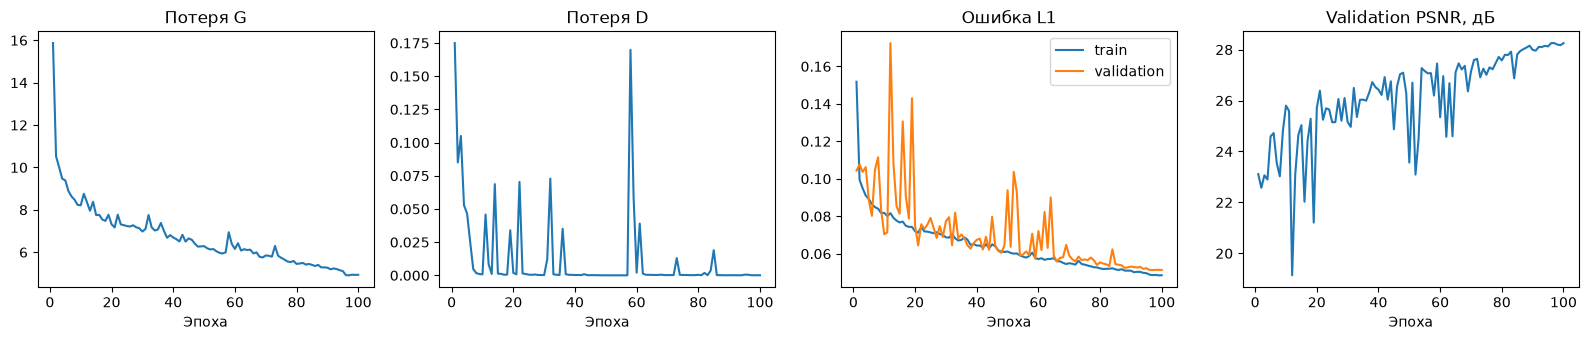

In [24]:
history = json.loads((RESULTS_DIR / 'history.json').read_text(encoding='utf-8'))
epochs = range(1, len(history['g_loss']) + 1)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].plot(epochs, history['g_loss'])
axes[1].plot(epochs, history['d_loss'])
axes[2].plot(epochs, history['train_l1'], label='train')
axes[2].plot(epochs, history['val_l1'], label='validation')
axes[2].legend()
axes[3].plot(epochs, history['val_psnr'])
for ax, title in zip(axes, ['Потеря G', 'Потеря D', 'Ошибка L1', 'Validation PSNR, дБ']):
    ax.set_title(title)
    ax.set_xlabel('Эпоха')
plt.tight_layout()
fig.savefig(RESULTS_DIR / 'training_curves.png', dpi=120)
plt.show()

In [17]:
def load_map_generator(checkpoint_path):
    model = UNetGenerator().to(DEVICE)
    model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))
    return model.eval()

Test L1: 0.0577; PSNR: 26.81 дБ


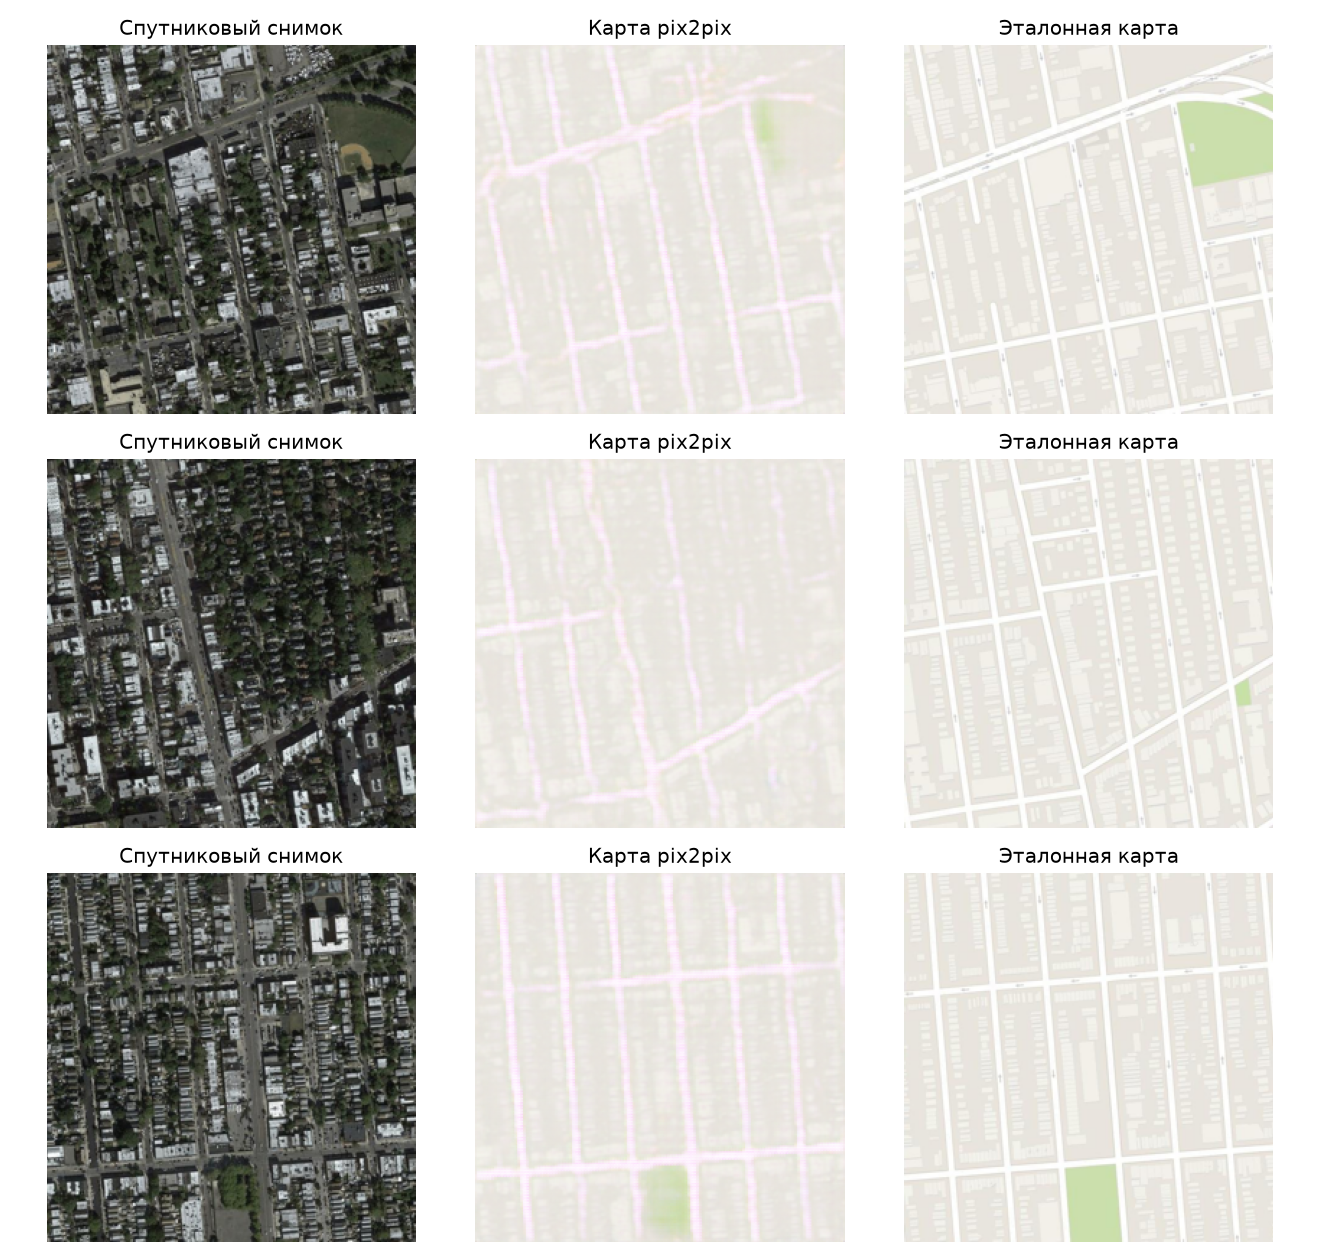

In [18]:
from IPython.display import display, Image as DisplayImage

trained_generator = load_map_generator(RESULTS_DIR / 'best_generator.pt')
test_metrics = evaluate_maps(trained_generator, test_loader)
print(f'Test L1: {test_metrics["l1"]:.4f}; PSNR: {test_metrics["psnr"]:.2f} дБ')
(RESULTS_DIR / 'test_metrics.json').write_text(json.dumps(test_metrics, indent=2), encoding='utf-8')
examples_path = save_map_examples(trained_generator, test_dataset, RESULTS_DIR / 'test_examples.png')
display(DisplayImage(filename=str(examples_path)))

## 8. Получение карты для своего снимка
Функция принимает отдельный спутниковый снимок PNG, JPG или BMP, приводит его
к 256×256 и сохраняет карту того же размера. Нормализация соответствует обучению.

In [21]:
@torch.no_grad()
def generate_map(model, input_path, output_path):
    with Image.open(input_path) as image:
        image = image.convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BICUBIC)
    tensor = (TF.to_tensor(image) * 2 - 1).unsqueeze(0).to(next(model.parameters()).device)
    model.eval()
    prediction = model(tensor)[0].cpu()
    result = TF.to_pil_image(((prediction + 1) / 2).clamp(0, 1))
    result.save(output_path)
    return result


# Подготавливаем существующий файл для демонстрации функции
satellite, _ = test_dataset[0]
TF.to_pil_image(((satellite + 1) / 2).clamp(0, 1)).save(RESULTS_DIR / 'demo_satellite.png')

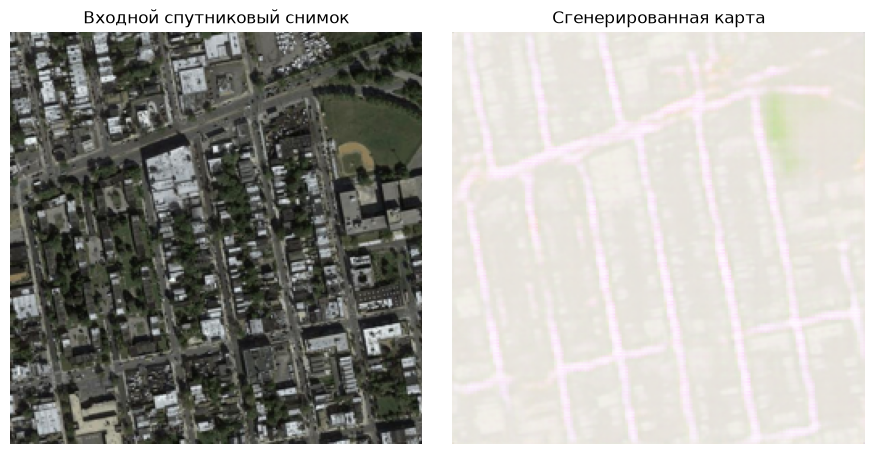

Карта сохранена: D:\projects\python\AIT\runs\pix2pix_maps\generated_map.png


In [22]:
INPUT_PATH = RESULTS_DIR / 'demo_satellite.png'  # Здесь можно указать свой снимок
OUTPUT_PATH = RESULTS_DIR / 'generated_map.png'
generated_map = generate_map(trained_generator, INPUT_PATH, OUTPUT_PATH)

with Image.open(INPUT_PATH) as source:
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
    axes[0].imshow(source.convert('RGB'))
    axes[1].imshow(generated_map)
for ax, title in zip(axes, ['Входной спутниковый снимок', 'Сгенерированная карта']):
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
fig.savefig(RESULTS_DIR / 'file_prediction.png', dpi=120)
plt.show()
print('Карта сохранена:', OUTPUT_PATH.resolve())

In [25]:
best_epoch = min(range(len(history['val_l1'])), key=history['val_l1'].__getitem__)
summary = {
    'epochs': len(history['g_loss']),
    'best_epoch': best_epoch + 1,
    'validation_l1': history['val_l1'][best_epoch],
    'validation_psnr': history['val_psnr'][best_epoch],
    'test_l1': test_metrics['l1'],
    'test_mae_0_1': test_metrics['l1'] / 2,
    'test_psnr': test_metrics['psnr'],
}
(RESULTS_DIR / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(f'Завершено эпох: {summary["epochs"]}; лучшая по validation L1: {summary["best_epoch"]}')
print(f'Validation: L1={summary["validation_l1"]:.4f}, PSNR={summary["validation_psnr"]:.2f} дБ')
print(f'Test: L1={summary["test_l1"]:.4f}, PSNR={summary["test_psnr"]:.2f} дБ')
print(f'MAE на test в диапазоне RGB [0, 1]: {summary["test_mae_0_1"]:.4f}')

Завершено эпох: 100; лучшая по validation L1: 97
Validation: L1=0.0513, PSNR=28.26 дБ
Test: L1=0.0577, PSNR=26.81 дБ
MAE на test в диапазоне RGB [0, 1]: 0.0288


**Вывод.** Подготовлены парные данные maps, реализованы U-Net и условный
PatchGAN, выполнено обучение pix2pix и оценка на отложенной test-выборке.
Лучшая модель выбиралась по validation L1; test не использовался для выбора весов.